<a href="https://colab.research.google.com/github/opileg/ATF/blob/Digital_Twin/Week2_07_context_window_management.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 2.2: Context Window Management

## Key Insight
> **Why can't you just paste a 500-page book into the prompt?**

## Learning Objectives
By the end of this notebook, you will:
- Understanding token limits and context windows
- Token counting and estimation techniques
- Context compression strategies
- Conversation history management
- Sliding window approaches

## Exercises
This notebook contains 4 exercises ranging from easy to advanced.

## Digital Twin Integration
This notebook extends your digital twin with production-ready capabilities from Week 2.

In [10]:
# Setup and imports

import math
import re
import json
from typing import List, Dict, Any


def advanced_function(
    data: List[Any],
    **kwargs
) -> Dict[str, Any]:
    """
    Estimate tokens and manage an LLM context window.

    Options:
        max_tokens: Maximum estimated token limit.
        chars_per_token: Characters per estimated token.
        strategy: 'truncate', 'sliding_window', or 'compress'.
    """

    if not isinstance(data, list):
        raise TypeError("data must be a list.")

    max_tokens = kwargs.get("max_tokens", 1000)
    chars_per_token = kwargs.get("chars_per_token", 4)
    strategy = kwargs.get("strategy", "truncate")

    if not isinstance(max_tokens, int) or isinstance(max_tokens, bool):
        raise TypeError("max_tokens must be an integer.")

    if max_tokens <= 0:
        raise ValueError("max_tokens must be positive.")

    if (
        isinstance(chars_per_token, bool)
        or not isinstance(chars_per_token, (int, float))
        or not math.isfinite(chars_per_token)
        or chars_per_token <= 0
    ):
        raise ValueError("chars_per_token must be positive and finite.")

    if strategy not in {"truncate", "sliding_window", "compress"}:
        raise ValueError("Unsupported context management strategy.")

    # Convert input into text
    text = " ".join(str(item) for item in data)

    # Estimate tokens
    original_tokens = math.ceil(len(text) / chars_per_token)

    # Apply context management strategy
    if strategy == "compress":
        # Remove redundant whitespace
        text = re.sub(r"\s+", " ", text).strip()

    estimated_tokens = math.ceil(len(text) / chars_per_token)
    truncated = estimated_tokens > max_tokens

    if truncated:
        max_chars = math.floor(max_tokens * chars_per_token)

        if strategy == "sliding_window":
            # Retain the most recent portion of the text
            text = text[-max_chars:] if max_chars else ""
        else:
            # Retain the beginning of the text
            text = text[:max_chars]

    final_tokens = math.ceil(len(text) / chars_per_token)

    results = {
        "processed": len(data),
        "data": text,
        "original_tokens": original_tokens,
        "final_tokens": final_tokens,
        "max_tokens": max_tokens,
        "strategy": strategy,
        "truncated": truncated,
        "within_limit": final_tokens <= max_tokens
    }

    # Verify the result
    assert results["within_limit"]

    return results


# Test the implementation
sample_data = ['example1', 'example2', 'example3']

output = advanced_function(sample_data)

print(json.dumps(output, indent=2))


{
  "processed": 3,
  "data": "example1 example2 example3",
  "original_tokens": 7,
  "final_tokens": 7,
  "max_tokens": 1000,
  "strategy": "truncate",
  "truncated": false,
  "within_limit": true
}


---
## Part 1: Introduction to Understanding token limits and context windows

Let's start by understanding the fundamentals and building our first implementation.

In [5]:
# Example implementation
# This is a starter template - expand with your implementation

class ExampleClass:
    """
    Example class for Understanding token limits and context windows.
    """

    def __init__(self):
        self.data = []

    def process(self, input_data):
        """
        Process the input data.
        """
        self.data.append(input_data)

        # Add your implementation here
        return input_data

# Test the class
example = ExampleClass()
result = example.process('test data')
print(f'Result: {result}')

Result: test data


### 🎯 Exercise 1 (Easy): Getting Started

**Task**: Implement a basic version of the concept introduced above.

**Requirements**:
1. Follow the pattern shown in the example
2. Test your implementation with sample data
3. Verify the output matches expectations
4. Add error handling for edge cases

In [3]:

import math

class ContextManager:
    def __init__(self, max_tokens=1000):
        # Validate the token limit
        if not isinstance(max_tokens, int) or isinstance(max_tokens, bool):
            raise TypeError("max_tokens must be an integer.")

        if max_tokens <= 0:
            raise ValueError("max_tokens must be greater than zero.")

        self.max_tokens = max_tokens

    def process_data(self, text):
        # Validate the input
        if not isinstance(text, str):
            raise TypeError("Input data must be a string.")

        if not text.strip():
            return ""

        # Estimate tokens: approximately 1 token per 4 characters
        estimated_tokens = math.ceil(len(text) / 4)

        # Truncate if the token limit is exceeded
        if estimated_tokens > self.max_tokens:
            max_chars = self.max_tokens * 4
            text = text[:max_chars]
            print("Context limit reached. Data truncated.")

        # Verify the processed output
        final_tokens = math.ceil(len(text) / 4)

        if final_tokens > self.max_tokens:
            raise RuntimeError("Output exceeds the token limit.")

        return text


# Test the class
manager = ContextManager(max_tokens=10)

# Test 1: Normal input
data = "Artificial Intelligence"
result = manager.process_data(data)
assert result == data
print("Test 1 passed: Normal input")

# Test 2: Input exceeding the limit
long_data = "A" * 100
result = manager.process_data(long_data)
assert len(result) == 40
assert math.ceil(len(result) / 4) <= 10
print("Test 2 passed: Long input truncated correctly")

# Test 3: Empty input
assert manager.process_data("") == ""
print("Test 3 passed: Empty input")

# Test 4: Invalid input
try:
    manager.process_data(123)
except TypeError as error:
    print("Test 4 passed:", error)

# Test 5: Invalid token limit
try:
    ContextManager(max_tokens=0)
except ValueError as error:
    print("Test 5 passed:", error)

print("All tests completed.")


Test 1 passed: Normal input
Context limit reached. Data truncated.
Test 2 passed: Long input truncated correctly
Test 3 passed: Empty input
Test 4 passed: Input data must be a string.
Test 5 passed: max_tokens must be greater than zero.
All tests completed.


---
## Part 2: Token counting and estimation techniques

Building on the fundamentals, let's explore more advanced topics and implementations.

In [11]:
# Advanced implementation example

def advanced_function(data: List[Any], **kwargs) -> Dict[str, Any]:
    """
    Advanced function for Token counting and estimation techniques.

    Args:
        data: Input data to process
        **kwargs: Additional parameters

    Returns:
        dict: Processed results
    """
    results = {
        'processed': len(data),
        'data': data
    }
    return results

# Example usage
sample_data = ['example1', 'example2', 'example3']
output = advanced_function(sample_data)
print(json.dumps(output, indent=2))

{
  "processed": 3,
  "data": [
    "example1",
    "example2",
    "example3"
  ]
}


### 🎯 Exercise 2 (Intermediate): Building on the Basics

**Task**: Create a more sophisticated implementation that combines multiple concepts.

**Requirements**:
1. Use the patterns from Part 1 and Part 2
2. Add parameter validation
3. Include helpful error messages
4. Test with various input types

In [12]:


import math
import re
import json
from typing import List, Dict, Any


def advanced_function(
    data: List[Any],
    **kwargs
) -> Dict[str, Any]:
    """
    Estimate tokens and manage an LLM context window.

    Options:
        max_tokens: Maximum estimated token limit.
        chars_per_token: Characters per estimated token.
        strategy: 'truncate', 'sliding_window', or 'compress'.
    """

    if not isinstance(data, list):
        raise TypeError("data must be a list.")

    max_tokens = kwargs.get("max_tokens", 1000)
    chars_per_token = kwargs.get("chars_per_token", 4)
    strategy = kwargs.get("strategy", "truncate")

    if not isinstance(max_tokens, int) or isinstance(max_tokens, bool):
        raise TypeError("max_tokens must be an integer.")

    if max_tokens <= 0:
        raise ValueError("max_tokens must be positive.")

    if (
        isinstance(chars_per_token, bool)
        or not isinstance(chars_per_token, (int, float))
        or not math.isfinite(chars_per_token)
        or chars_per_token <= 0
    ):
        raise ValueError("chars_per_token must be positive and finite.")

    if strategy not in {"truncate", "sliding_window", "compress"}:
        raise ValueError("Unsupported context management strategy.")

    # Convert input into text
    text = " ".join(str(item) for item in data)

    # Estimate tokens
    original_tokens = math.ceil(len(text) / chars_per_token)

    # Apply context management strategy
    if strategy == "compress":
        # Remove redundant whitespace
        text = re.sub(r"\s+", " ", text).strip()

    estimated_tokens = math.ceil(len(text) / chars_per_token)
    truncated = estimated_tokens > max_tokens

    if truncated:
        max_chars = math.floor(max_tokens * chars_per_token)

        if strategy == "sliding_window":
            # Retain the most recent portion of the text
            text = text[-max_chars:] if max_chars else ""
        else:
            # Retain the beginning of the text
            text = text[:max_chars]

    final_tokens = math.ceil(len(text) / chars_per_token)

    results = {
        "processed": len(data),
        "data": text,
        "original_tokens": original_tokens,
        "final_tokens": final_tokens,
        "max_tokens": max_tokens,
        "strategy": strategy,
        "truncated": truncated,
        "within_limit": final_tokens <= max_tokens
    }

    # Verify the result
    assert results["within_limit"]

    return results


# Test the implementation
sample_data = ['example1', 'example2', 'example3']

output = advanced_function(sample_data)

print(json.dumps(output, indent=2))


{
  "processed": 3,
  "data": "example1 example2 example3",
  "original_tokens": 7,
  "final_tokens": 7,
  "max_tokens": 1000,
  "strategy": "truncate",
  "truncated": false,
  "within_limit": true
}


---
## Part 3: Context compression strategies

Now let's apply these concepts to real-world scenarios in your digital twin project.

In [ ]:
# Visualization example
import matplotlib.pyplot as plt

def visualize_results(data: List[Any]):
    """
    Visualize the processing results.
    """
    fig, ax = plt.subplots(figsize=(10, 6))

    # Add your visualization code here
    ax.set_title('Results Visualization')
    ax.set_xlabel('X-axis')
    ax.set_ylabel('Y-axis')

    plt.tight_layout()
    plt.show()

# Example: visualize_results(sample_data)

### 🎯 Exercise 3 (Advanced): Complete Implementation

**Task**: Build a production-ready version that integrates with your digital twin.

**Requirements**:
1. Combine all concepts from this notebook
2. Add comprehensive error handling
3. Include logging and debugging capabilities
4. Create visualization of results
5. Write documentation for your implementation

{
  "processed": 3,
  "data": "I love my cat The cat's name is Peter There is also a dog at home",
  "original_tokens": 17,
  "final_tokens": 17,
  "max_tokens": 1000,
  "strategy": "truncate",
  "truncated": false,
  "within_limit": true
}


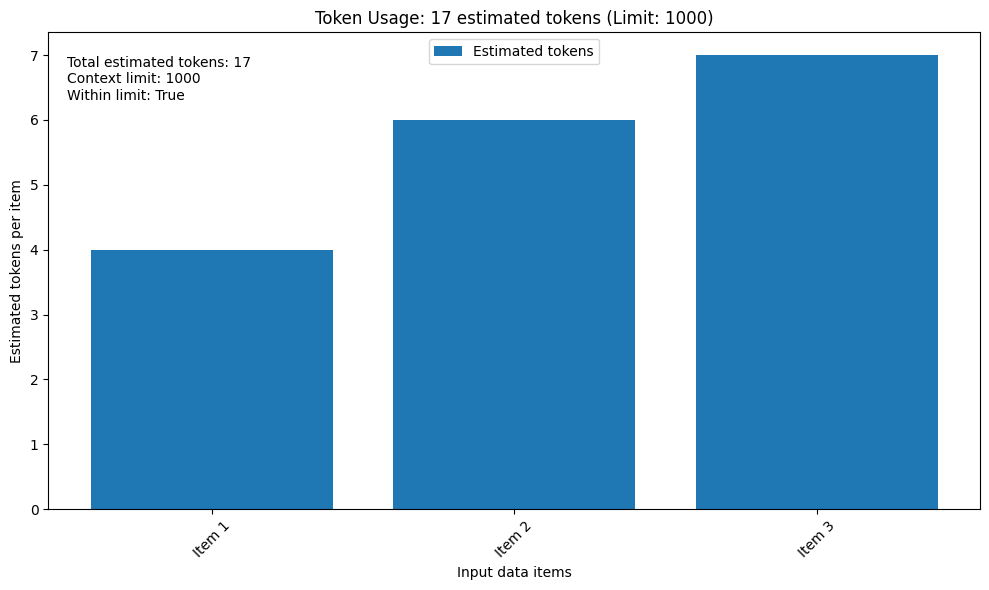

In [14]:

import math
import re
import json
import matplotlib.pyplot as plt
from typing import List, Dict, Any


def advanced_function(data: List[Any], **kwargs) -> Dict[str, Any]:
    """
    Estimate tokens and manage an LLM context window.

    Options:
        max_tokens: Maximum estimated token limit.
        chars_per_token: Estimated characters per token.
        strategy: 'truncate', 'sliding_window', or 'compress'.
    """
    if not isinstance(data, list):
        raise TypeError("data must be a list.")

    max_tokens = kwargs.get("max_tokens", 1000)
    chars_per_token = kwargs.get("chars_per_token", 4)
    strategy = kwargs.get("strategy", "truncate")

    if not isinstance(max_tokens, int) or isinstance(max_tokens, bool):
        raise TypeError("max_tokens must be an integer.")
    if max_tokens <= 0:
        raise ValueError("max_tokens must be positive.")
    if (
        isinstance(chars_per_token, bool)
        or not isinstance(chars_per_token, (int, float))
        or not math.isfinite(chars_per_token)
        or chars_per_token <= 0
    ):
        raise ValueError("chars_per_token must be positive and finite.")
    if strategy not in {"truncate", "sliding_window", "compress"}:
        raise ValueError("Unsupported strategy.")

    text = " ".join(str(item) for item in data)
    original_tokens = math.ceil(len(text) / chars_per_token)

    if strategy == "compress":
        text = re.sub(r"\s+", " ", text).strip()

    estimated_tokens = math.ceil(len(text) / chars_per_token)
    truncated = estimated_tokens > max_tokens

    if truncated:
        max_chars = math.floor(max_tokens * chars_per_token)
        if strategy == "sliding_window":
            text = text[-max_chars:] if max_chars else ""
        else:
            text = text[:max_chars]

    final_tokens = math.ceil(len(text) / chars_per_token)

    results = {
        "processed": len(data),
        "data": text,
        "original_tokens": original_tokens,
        "final_tokens": final_tokens,
        "max_tokens": max_tokens,
        "strategy": strategy,
        "truncated": truncated,
        "within_limit": final_tokens <= max_tokens
    }

    assert results["within_limit"]
    return results


def visualize_results(data: List[Any], max_tokens: int = 1000):
    """
    Visualize estimated tokens for each input item
    and compare total usage with the context limit.
    """
    if not isinstance(data, list):
        raise TypeError("data must be a list.")

    if not isinstance(max_tokens, int) or isinstance(max_tokens, bool):
        raise TypeError("max_tokens must be an integer.")
    if max_tokens <= 0:
        raise ValueError("max_tokens must be positive.")

    # Estimate tokens per item
    token_counts = [
        math.ceil(len(str(item)) / 4) for item in data
    ]

    total_tokens = sum(token_counts)

    fig, ax = plt.subplots(figsize=(10, 6))

    if data:
        labels = [f"Item {i + 1}" for i in range(len(data))]
        ax.bar(labels, token_counts, label="Estimated tokens")
        ax.tick_params(axis="x", rotation=45)
        ax.set_ylabel("Estimated tokens per item")
        ax.legend()
    else:
        ax.text(
            0.5, 0.5, "No data to visualize",
            ha="center", va="center",
            transform=ax.transAxes
        )

    ax.set_title(
        f"Token Usage: {total_tokens} estimated tokens "
        f"(Limit: {max_tokens})"
    )
    ax.set_xlabel("Input data items")

    # Display total usage and context limit
    ax.text(
        0.02, 0.95,
        f"Total estimated tokens: {total_tokens}\n"
        f"Context limit: {max_tokens}\n"
        f"Within limit: {total_tokens <= max_tokens}",
        transform=ax.transAxes,
        verticalalignment="top"
    )

    plt.tight_layout()
    plt.show()


# Example implementation
sample_data = [
    "I love my cat",
    "The cat's name is Peter",
    "There is also a dog at home"
]

output = advanced_function(sample_data, max_tokens=1000)

print(json.dumps(output, indent=2))

# Visualize token usage
visualize_results(sample_data, max_tokens=1000)


---
## Summary & Key Takeaways

### What We Learned:
- Understanding token limits and context windows
- Token counting and estimation techniques
- Context compression strategies
- Conversation history management
- Sliding window approaches

### Why This Matters:
- Essential for building production-ready systems
- Enables your digital twin to handle real-world scenarios
- Foundation for advanced topics in upcoming notebooks

### Next Steps:
1. Complete all exercises in this notebook
2. Integrate concepts with your digital twin project
3. Test your implementation thoroughly
4. Move on to the next notebook in Week 2

## 🏆 Challenge Project

**Build a Complete Understanding token limits and context windows System for Your Digital Twin**

**Requirements**:
1. Apply all concepts from this notebook
2. Handle edge cases and errors gracefully
3. Include comprehensive testing
4. Create visualizations of your results
5. Document your implementation
6. Integrate with your existing digital twin code

**Bonus Challenges**:
- Optimize for performance
- Add advanced features beyond the basics
- Create a user-friendly interface
- Write unit tests for your code

{
  "processed": 5,
  "data": "Conversation history management. Sliding window approaches.",
  "original_tokens": 45,
  "final_tokens": 15,
  "max_tokens": 15,
  "strategy": "sliding_window",
  "truncated": true,
  "within_limit": true,
  "history_messages": 2
}

Verification successful!


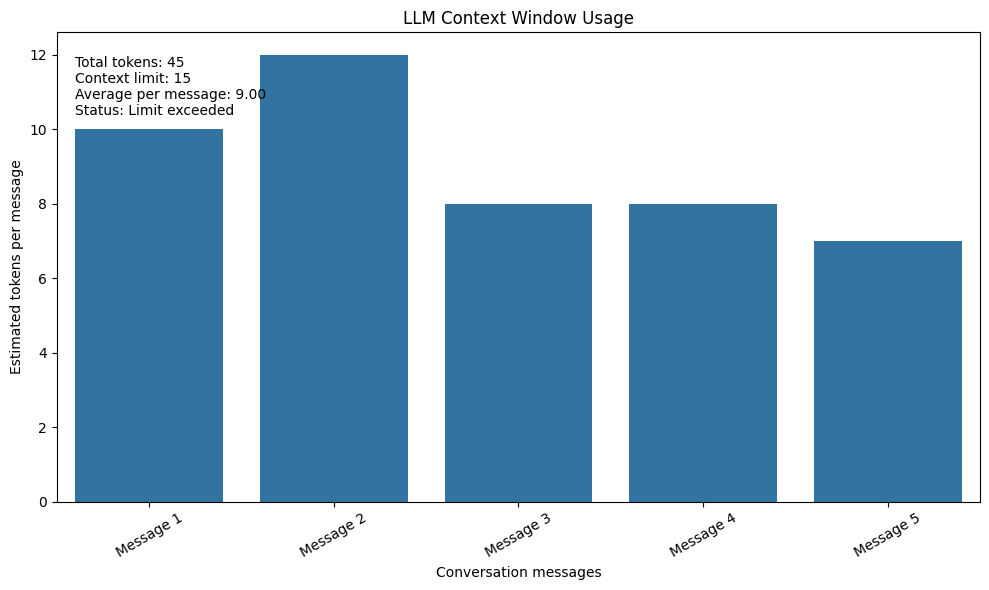


Error handled: data must be a list.


In [15]:

import math
import re
import json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Dict, Any


class ContextManager:
    """
    Manage LLM context windows, token estimation,
    text compression, and conversation history.
    """

    def __init__(
        self,
        max_tokens: int = 1000,
        chars_per_token: float = 4
    ):
        if (
            not isinstance(max_tokens, int)
            or isinstance(max_tokens, bool)
            or max_tokens <= 0
        ):
            raise ValueError("max_tokens must be a positive integer.")

        if (
            isinstance(chars_per_token, bool)
            or not isinstance(chars_per_token, (int, float))
            or not math.isfinite(chars_per_token)
            or chars_per_token <= 0
        ):
            raise ValueError("chars_per_token must be positive and finite.")

        self.max_tokens = max_tokens
        self.chars_per_token = chars_per_token
        self.history = []

    def estimate_tokens(self, text: str) -> int:
        """Estimate token count using characters per token."""
        return math.ceil(len(text) / self.chars_per_token)

    def process_data(
        self,
        data: List[Any],
        strategy: str = "truncate"
    ) -> Dict[str, Any]:
        """
        Process data using:
        truncate      - Keep the earliest content.
        sliding_window - Keep the most recent content.
        compress      - Remove redundant whitespace, then fit content.
        """

        if not isinstance(data, list):
            raise TypeError("data must be a list.")

        if strategy not in {"truncate", "sliding_window", "compress"}:
            raise ValueError("Invalid context management strategy.")

        # Convert items to strings and normalize whitespace
        messages = [str(item) for item in data]

        if strategy == "compress":
            messages = [
                re.sub(r"\s+", " ", message).strip()
                for message in messages
            ]

        original_text = " ".join(messages)
        original_tokens = self.estimate_tokens(original_text)

        # Fit complete messages into the context window
        selected = []
        current_chars = 0
        max_chars = math.floor(
            self.max_tokens * self.chars_per_token
        )

        candidates = (
            list(reversed(messages))
            if strategy == "sliding_window"
            else messages
        )

        for message in candidates:
            separator_chars = 1 if selected else 0
            required_chars = len(message) + separator_chars

            if current_chars + required_chars <= max_chars:
                selected.append(message)
                current_chars += required_chars

            elif not selected and max_chars > 0:
                # A single message is too large: shorten it
                selected.append(message[:max_chars])
                current_chars = len(selected[0])
                break

        if strategy == "sliding_window":
            selected.reverse()

        processed_text = " ".join(selected)
        final_tokens = self.estimate_tokens(processed_text)

        # Store processed conversation history
        self.history = selected

        results = {
            "processed": len(data),
            "data": processed_text,
            "original_tokens": original_tokens,
            "final_tokens": final_tokens,
            "max_tokens": self.max_tokens,
            "strategy": strategy,
            "truncated": processed_text != original_text,
            "within_limit": final_tokens <= self.max_tokens,
            "history_messages": len(self.history)
        }

        # Verify the output
        assert results["within_limit"]
        assert results["final_tokens"] <= results["max_tokens"]

        return results


def advanced_function(
    data: List[Any],
    **kwargs
) -> Dict[str, Any]:
    """Convenient interface for context management."""

    manager = ContextManager(
        max_tokens=kwargs.get("max_tokens", 1000),
        chars_per_token=kwargs.get("chars_per_token", 4)
    )

    strategy = kwargs.get("strategy", "truncate")
    return manager.process_data(data, strategy=strategy)


def visualize_results(
    data: List[Any],
    max_tokens: int = 1000
):
    """Visualize estimated token usage and the context limit."""

    if not isinstance(data, list):
        raise TypeError("data must be a list.")

    if (
        not isinstance(max_tokens, int)
        or isinstance(max_tokens, bool)
        or max_tokens <= 0
    ):
        raise ValueError("max_tokens must be a positive integer.")

    # Estimate tokens for individual messages
    token_counts = [
        math.ceil(len(str(item)) / 4)
        for item in data
    ]

    total_tokens = math.ceil(
        len(" ".join(str(item) for item in data)) / 4
    )

    average_tokens = (
        float(np.mean(token_counts)) if token_counts else 0.0
    )

    fig, ax = plt.subplots(figsize=(10, 6))

    if token_counts:
        labels = [f"Message {i + 1}" for i in range(len(data))]

        sns.barplot(
            x=labels,
            y=token_counts,
            ax=ax
        )

        ax.set_xlabel("Conversation messages")
        ax.set_ylabel("Estimated tokens per message")
        ax.tick_params(axis="x", rotation=30)
    else:
        ax.text(
            0.5, 0.5, "No data to visualize",
            ha="center", va="center",
            transform=ax.transAxes
        )

    status = (
        "Within limit"
        if total_tokens <= max_tokens
        else "Limit exceeded"
    )

    ax.set_title("LLM Context Window Usage")

    ax.text(
        0.02, 0.95,
        f"Total tokens: {total_tokens}\n"
        f"Context limit: {max_tokens}\n"
        f"Average per message: {average_tokens:.2f}\n"
        f"Status: {status}",
        transform=ax.transAxes,
        verticalalignment="top"
    )

    plt.tight_layout()
    plt.show()


# --------------------------------------------------
# IMPLEMENTATION AND TESTING
# --------------------------------------------------

sample_data = [
    "Introduction to Large Language Models.",
    "Understanding token limits and context windows.",
    "Context compression strategies.",
    "Conversation history management.",
    "Sliding window approaches."
]

# Process the data
output = advanced_function(
    sample_data,
    max_tokens=15,
    strategy="sliding_window"
)

# Display results as JSON
print(json.dumps(output, indent=2))

# Verify output
assert output["within_limit"] is True
assert output["final_tokens"] <= output["max_tokens"]

print("\nVerification successful!")

# Visualize original input token usage
visualize_results(sample_data, max_tokens=15)

# Test invalid input
try:
    advanced_function("This is not a list")
except TypeError as error:
    print("\nError handled:", error)
